# Sprint 2 – Notebook 9: Outlier Detection

# 1. What are Outliers?

Outliers are data points that are significantly different from most other observations in a dataset.

An outlier may be unusually high or unusually low compared to the remaining values.

Outliers can occur because of:
- Data entry errors.
- Measurement errors.
- Unusual events.
- Natural variation in data.
- Genuine exceptional observations.

Real-world example

Suppose the marks of students are:

45, 50, 55, 60, 65, 70, 98

The mark 98 is much higher than most of the other marks, but it is not necessarily an outlier. It may simply represent a student who performed exceptionally well.

Now consider:

45, 50, 55, 60, 65, 70, 200

The mark 200 is impossible if the maximum mark is 100. This may be a data entry error or invalid observation.
Why are Outliers important?
- They can affect the mean.
- They can increase variance and standard deviation.
- They can affect Machine Learning model performance.
- They can influence regression models.
- They may indicate data quality problems.
- They may contain important information.

AI/ML relevance

Outlier detection is used during data preprocessing to identify unusual observations before training models.

Outliers can affect algorithms such as Linear Regression, K-Means Clustering and other distance-based or statistical methods.

# 2. Main Dataset

We will create a dataset containing student marks, including one unusually high value.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

marks = [45, 50, 52, 55, 58, 60, 62, 65, 68, 70, 72, 75, 78, 80, 200]

df = pd.DataFrame({
    "Exam_Marks": marks
})

df

,Exam_Marks
0,45
1,50
2,52
3,55
4,58
5,60
6,62
7,65
8,68
9,70


# 3. Types of Outliers

Outliers can be categorized into different types.

3.1 Point Outliers

A point outlier is a single observation that is significantly different from other observations.

Example: One student has a mark of 200 when most marks are between 45 and 80.

3.2 Contextual Outliers

A contextual outlier is an observation that is unusual in a specific context.

Example: Scoring 90 may be normal in one examination but unusually high in a very difficult examination where most students score below 30.

3.3 Collective Outliers

Collective outliers are a group of observations that together form an unusual pattern.

Example: A series of unusually high exam marks recorded for a particular class may indicate an unusual pattern in the data.

Interpretation

Different types of outliers require different detection methods. A single numerical method may not identify every type of outlier.

# 4. Detecting Outliers

Outliers can be detected using several techniques.
- IQR Method
- Z-Score Method
- Box Plot
- Scatter Plot

We will use the IQR Method and Z-Score Method in this notebook.

Why detect outliers?

Outlier detection helps us:
- Identify unusual observations.
- Investigate incorrect data.
- Improve data quality.
- Understand data distribution.
- Prepare data for Machine Learning.

# 5. IQR Method

What is IQR?

IQR stands for Interquartile Range.

It measures the spread of the middle 50% of the data.

The IQR is calculated by subtracting the first quartile (Q1) from the third quartile (Q3).

In [2]:
Q1 = df["Exam_Marks"].quantile(0.25)
Q3 = df["Exam_Marks"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

Q1: 56.5
Q3: 73.5
IQR: 17.0
Lower Bound: 31.0
Upper Bound: 99.0


Identify Outliers Using IQR

In [3]:
outliers = df[
    (df["Exam_Marks"] < lower_bound) |
    (df["Exam_Marks"] > upper_bound)
]

print("Outliers:")
print(outliers)

Outliers:
    Exam_Marks
14         200


# 6. Z-Score Method

What is Z-Score?

Z-Score measures how far a data point is from the mean in terms of standard deviations.

It helps identify values that are unusually far from the average.

Outlier Rule

A common rule is:
- Z-Score greater than +3: potential high outlier.
- Z-Score less than -3: potential low outlier.
- Z-Score between -3 and +3: generally not flagged by this rule.

Note: This is a commonly used rule, not a universal definition of an outlier.

In [4]:
mean = df["Exam_Marks"].mean()
std = df["Exam_Marks"].std()

df["Z_Score"] = (df["Exam_Marks"] - mean) / std

df

,Exam_Marks,Z_Score
0,45,-0.753044
1,50,-0.616952
2,52,-0.562515
3,55,-0.480860
4,58,-0.399204
5,60,-0.344767
6,62,-0.290330
7,65,-0.208675
8,68,-0.127020
9,70,-0.072583


Interpretation

    The Z-Score tells us how many standard deviations each mark is away from the mean.

    A large positive Z-Score indicates a value far above the mean.

    A large negative Z-Score indicates a value far below the mean.

Detect Outliers Using Z-Score

In [5]:
z_outliers = df[
    (df["Z_Score"] > 3) |
    (df["Z_Score"] < -3)
]

print("Z-Score Outliers:")
print(z_outliers)

Z-Score Outliers:
    Exam_Marks   Z_Score
14         200  3.465819


# 7. Box Plot

What is a Box Plot?

A box plot is a graphical representation of the distribution of numerical data.

It displays:
- Minimum (excluding flagged outliers).
- First Quartile (Q1).
- Median (Q2).
- Third Quartile (Q3).
- Maximum (excluding flagged outliers).
- Potential outliers.

Why is a Box Plot important?
- Helps identify potential outliers.
- Shows the spread of data.
- Displays the median and quartiles.
- Helps compare distributions.
- Useful during EDA.

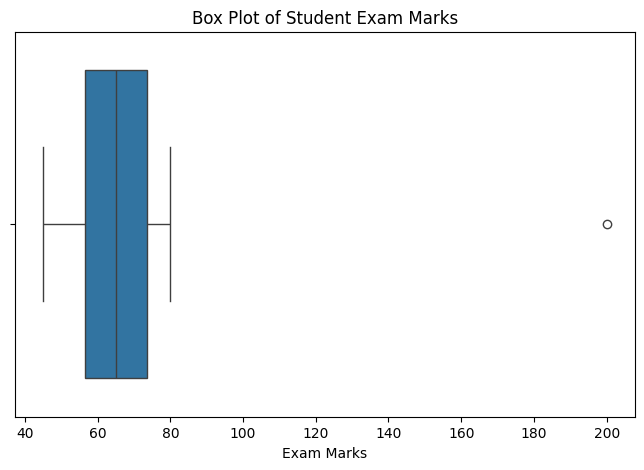

In [6]:
plt.figure(figsize=(8, 5))

sns.boxplot(x=df["Exam_Marks"])

plt.title("Box Plot of Student Exam Marks")
plt.xlabel("Exam Marks")

plt.show()

# 8. Scatter Plot

What is a Scatter Plot?

A scatter plot displays individual data points using dots on a graph.

It helps us identify relationships, patterns and unusual observations.

Why is a Scatter Plot important?

- Helps identify unusual values.
- Shows relationships between variables.
- Helps identify clusters.
- Helps detect patterns.
- Useful during EDA.

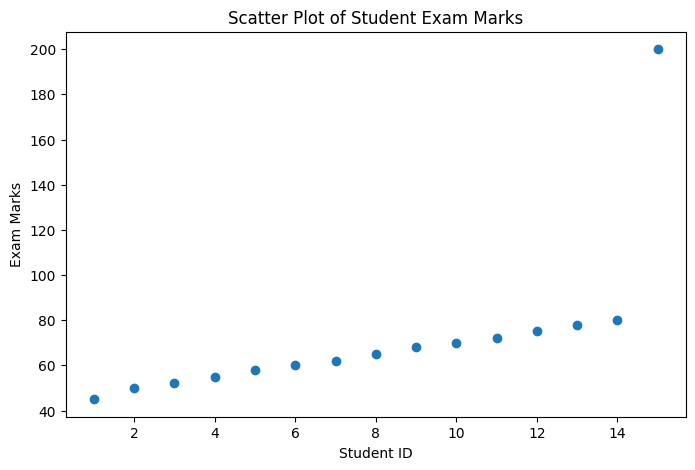

In [7]:
student_ids = range(1, len(df) + 1)

plt.figure(figsize=(8, 5))

plt.scatter(student_ids, df["Exam_Marks"])

plt.xlabel("Student ID")
plt.ylabel("Exam Marks")
plt.title("Scatter Plot of Student Exam Marks")

plt.show()

# 9. Compare IQR and Z-Score Methods

IQR Method	Z-Score Method

Uses quartiles.	Uses mean and standard deviation

Uses Q1 and Q3.	Uses mean and standard deviation

Uses 1.5 × IQR for boundaries.	Commonly uses ±3

Generally less affected by extreme values.	Can be influenced by extreme values

Useful for skewed distributions	More suitable when data is approximately normally distributed


Interpretation

Both methods help detect potential outliers.

The IQR method is often useful when the data is skewed or contains extreme values. The Z-Score method is often used when the data is approximately normally distributed.

Neither method is guaranteed to detect all outliers correctly.

# 10. Handling Outliers

After detecting outliers, we should investigate them before deciding what to do.
Common Methods

- Remove outliers when they are invalid observations and removal is justified.
- Correct values when a verified data entry error exists.
- Cap extreme values when justified using a suitable method.
- Transform data when appropriate.
- Keep outliers when they represent genuine observations.

Python Example – Compare Original and Filtered Data

We will create a separate dataset without the IQR-flagged outlier for comparison only.

In [8]:
df_without_outliers = df[
    (df["Exam_Marks"] >= lower_bound) &
    (df["Exam_Marks"] <= upper_bound)
]

df_without_outliers

,Exam_Marks,Z_Score
0,45,-0.753044
1,50,-0.616952
2,52,-0.562515
3,55,-0.480860
4,58,-0.399204
5,60,-0.344767
6,62,-0.290330
7,65,-0.208675
8,68,-0.127020
9,70,-0.072583


Compare the Mean

In [9]:
print("Original Mean:", df["Exam_Marks"].mean())

print("Filtered Mean:",
      df_without_outliers["Exam_Marks"].mean())

Original Mean: 72.66666666666667
Filtered Mean: 63.57142857142857


# 11. Outlier Detection in AI/ML

Outlier detection is an important step in Data Preprocessing.
Applications

- Data Cleaning: Identifying incorrect or unusual values.
- Linear Regression: Extreme values can influence regression coefficients.
- K-Means Clustering: Outliers may affect cluster centers.
- Fraud Detection: Unusual transaction patterns may indicate suspicious activity.
- Anomaly Detection: Identifying unusual behavior or patterns.

Example

When predicting student exam marks, an invalid mark of 200 may negatively affect statistical analysis or model training.

Detecting and investigating such values helps improve data quality.

# 12. Advantages of Outlier Detection

1. Helps improve data quality.
2. Identifies unusual observations.
3. Helps detect data entry errors.
4. Can improve some Machine Learning models.
5. Helps understand data distribution.
6. Useful during Exploratory Data Analysis.

# 13. Limitations of Outlier Detection
1. Genuine observations may be incorrectly identified as outliers.
2. Different methods may identify different outliers.
3. Outliers may affect statistical calculations.
4. Small datasets may make detection difficult.
5. Removing outliers may result in information loss.
6. No single method is suitable for every dataset.